# 极客项目 ch03：Conway 生命游戏

对应《Python Playground》第 3 章（Conway's Game of Life）。`FuncAnimation` 的 GUI 动画 cell 保留但不执行；用固定种子（2026）的静态帧演示替代。

In [1]:
# ===== 公共设置 =====
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

np.random.seed(2026)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False


## 书 3.3.1–3.3.2 网格与初始条件

活动格 255、空格 0；`randomGrid()` 以 p=0.2 撒活格，`addGlider()` 放一个滑翔机图案。

In [2]:
# ===== 书 3.3.1/3.3.2 节 randomGrid() + addGlider() =====
ON = 255
OFF = 0
vals = [ON, OFF]

def randomGrid(N):
    """returns a grid of NxN random values"""
    return np.random.choice(vals, N*N, p=[0.2, 0.8]).reshape(N, N)

def addGlider(i, j, grid):
    """adds a glider with top left cell at (i, j)"""
    glider = np.array([[0,    0, 255],
                       [255,  0, 255],
                       [0,  255, 255]])
    grid[i:i+3, j:j+3] = glider


## 书 3.3.3–3.3.4 边界条件与规则

下标用 `% N` 折返（环形边界/圆环面）；对每个细胞求 8 邻居和，套 Conway 四规则。

In [3]:
# ===== 书 3.3.4 节 update() =====
def update(frameNum, img, grid, N):
    # copy grid since we require 8 neighbors for calculation
    # and we go line by line
    newGrid = grid.copy()
    for i in range(N):
        for j in range(N):
            # compute 8-neighbor sum using toroidal boundary conditions
            # x and y wrap around so the simulation takes place on a torus
            total = int((grid[i, (j-1)%N] + grid[i, (j+1)%N] +
                         grid[(i-1)%N, j] + grid[(i+1)%N, j] +
                         grid[(i-1)%N, (j-1)%N] + grid[(i-1)%N, (j+1)%N] +
                         grid[(i+1)%N, (j-1)%N] + grid[(i+1)%N, (j+1)%N])/255)
            # apply Conway's rules
            if grid[i, j] == ON:
                if (total < 2) or (total > 3):
                    newGrid[i, j] = OFF
            else:
                if total == 3:
                    newGrid[i, j] = ON
    # update data
    img.set_data(newGrid)
    grid[:] = newGrid[:]
    return img,


## 书 3.3.5–3.3.6 组装动画（FuncAnimation，不执行）

> 原书用 `FuncAnimation` 逐帧刷新（GUI 窗口），无头环境不执行；argparse 略。下方演示 cell 以同一个 `update()` 逐帧推进、抽帧出静态图。

In [ ]:
# ===== 书 3.3.6 节 组装动画（不执行：GUI 动画）=====
# set grid size
N = 100

# set animation update interval
updateInterval = 50

# declare grid：初始条件二选一（随机 or 滑翔机）
grid = randomGrid(N)

# set up animation
fig, ax = plt.subplots()
img = ax.imshow(grid, interpolation='nearest')
ani = animation.FuncAnimation(fig, update, fargs=(img, grid, N, ),
                              frames=10,
                              interval=updateInterval,
                              save_count=50)

plt.show()

## 演示：静态帧

上排：50×50 随机初始网格（t=0/10/30/60）；下排：12×12 环形边界上的滑翔机（t=0/16/32/48，48 步恰绕环面一周回到原位）。

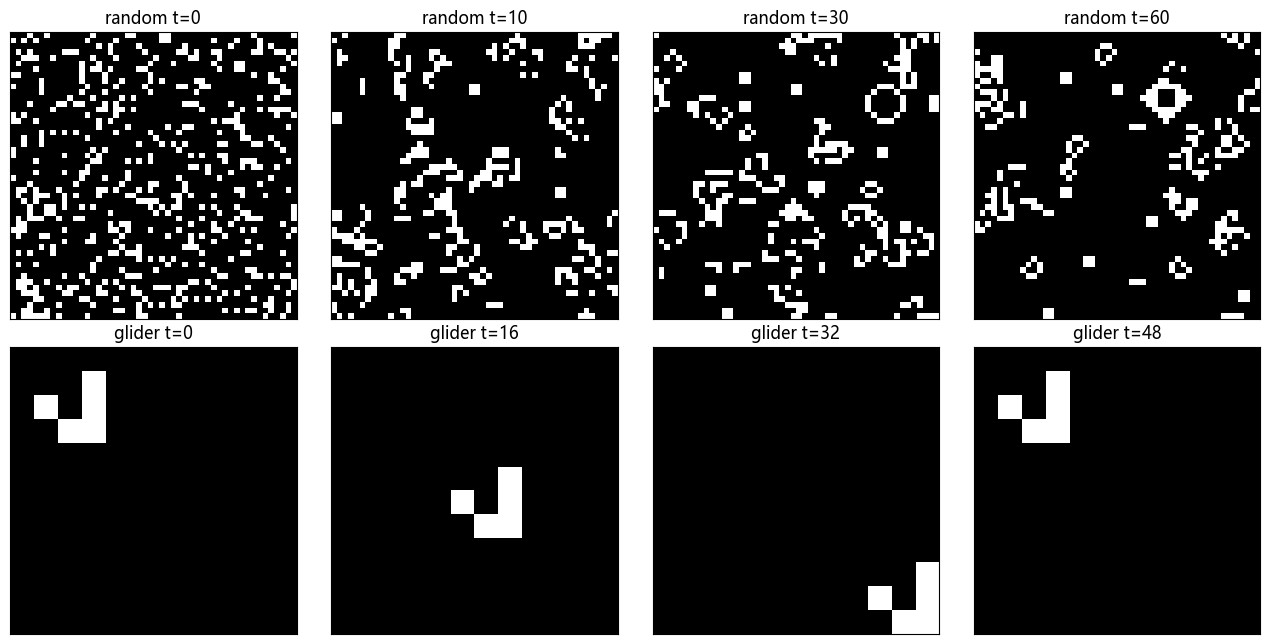

In [4]:
# ===== 演示：静态帧（FuncAnimation 的离线替代）=====
np.random.seed(2026)

class _StubImg:                        # 吃掉 update() 里的 img.set_data()
    def set_data(self, *_):
        pass

def step(grid, N):
    update(0, _StubImg(), grid, N)

# (a) 50×50 随机初始条件：t=0/10/30/60
N = 50
grid = randomGrid(N)
snaps = [(0, grid.copy())]
for t in range(1, 61):
    step(grid, N)
    if t in (10, 30, 60):
        snaps.append((t, grid.copy()))

# (b) 滑翔机在 12×12 环形边界上折返
G = 12
ggrid = np.zeros(G*G).reshape(G, G)
addGlider(1, 1, ggrid)
gsnaps = [(0, ggrid.copy())]
for t in range(1, 49):
    step(ggrid, G)
    if t in (16, 32, 48):
        gsnaps.append((t, ggrid.copy()))

fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for axi, (t, snap) in zip(axes[0], snaps):
    axi.imshow(snap, interpolation='nearest', cmap='gray')
    axi.set_title('random t=%d' % t); axi.set_xticks([]); axi.set_yticks([])
for axi, (t, snap) in zip(axes[1], gsnaps):
    axi.imshow(snap, interpolation='nearest', cmap='gray')
    axi.set_title('glider t=%d' % t); axi.set_xticks([]); axi.set_yticks([])
plt.tight_layout()
plt.show()